# Cuda k-means

**Naam:** THOMAS TIMMERMANS & MILAN MURONI

**Studentennummer:** _2365790_ & _2262576_



## 0. Gekozen setup

| Parameter | Waarde |
|---|---|
| Dataset | *1M_1000000x4.csv* |
| Aantal punten *n* | *1 000 000* |
| Aantal dimensies *d* | *4* |
| *k* (< 100) | *15* |
| repetitions (< 200) | *10* |
| seed | *2262576* |
| Aantal herhaalde metingen per configuratie | *3* |
| Aantal threads | *512* |
| Block-aantallen | *1 2 4 8 16 32 64 108 216 432 864* |
| vsc node | *wice a100 (108SM)* |
| Compiler + flags | *nvcc (CUDA 11.7.0 + GCC 10.3.0) met -O3 -DNDEBUG -gencode arch=compute_80,code=sm_80* |

## 1. Werkwijze


### IPV find_closest_centroid_index_and_distance & average_of_points_with_cluster een kernel die beiden in ee stap doet

```cpp
__global__ void assign_and_accumulate_kernel(const double *allData, const double *centroids, int *clusters, double *blockSums, int *blockCounts, double *blockDist, int *changed, size_t numRows, size_t numCols, int numClusters)
{
	//geheugen per block
    extern __shared__ double smem[]; // blok geheugen dat we zelf in drie kappen
    double *s_sums = smem; // lijst van double waarden om de som van de punten per cluster bij te houden, om later nieuwe centroids te berekenen(teller)
	double *s_dist = &smem[(size_t)numClusters * numCols]; // een double waarde om de som van de afstanden tot de dichtstbijzijnde cluster bij te houden per block, om te kijken welke repetitie de beste is
 	int *s_counts = (int*)&s_dist[1]; // een int array om het aantal punten per cluster bij te houden,om later nieuwe centroids te berekenen(Noemer)
	
    // Shared memory op 0 zetten per block
    for (size_t i = threadIdx.x; i < (size_t)numClusters * numCols; i += blockDim.x)
        s_sums[i] = 0.0;
    for (int j = threadIdx.x; j < numClusters; j += blockDim.x)
        s_counts[j] = 0;
    if (threadIdx.x == 0)
        s_dist[0] = 0.0;
    __syncthreads();

	//stride is totaal aantal threads op hele gpu, elke thread pakt zijn eigen punten, en als die klaar is pakt hij de volgende punten die nog niet gedaan zijn
    size_t stride = (size_t)gridDim.x * blockDim.x;
    for (size_t p = (size_t)blockIdx.x * blockDim.x + threadIdx.x; p < numRows; p += stride) {
        int closestCluster = -1;
        double minDistanceSq = DBL_MAX;

		//uit functie find_closest_cenroid_index_and_distace
        for (int j = 0; j < numClusters; ++j) {
            double currentDistSq = 0.0;
            for (size_t d = 0; d < numCols; ++d) {
                double diff = allData[p * numCols + d] - centroids[(size_t)j * numCols + d];
                currentDistSq += diff * diff;
            }

            if (currentDistSq < minDistanceSq) {
                minDistanceSq = currentDistSq;
                closestCluster = j;
            }
        }

		//als cluster veranderd is zet dan changed op 1 zodat de host weet dat er nog een stap nodig is
        if (clusters[p] != closestCluster) {
            clusters[p] = closestCluster;
            *changed = 1;
        }

        // voor later nieuwe centroids berekenen, subtotaal per block in shared memory,
        atomicAdd(&s_dist[0], minDistanceSq);
        atomicAdd(&s_counts[closestCluster], 1);
        for (size_t d = 0; d < numCols; ++d) {
            atomicAdd(&s_sums[(size_t)closestCluster * numCols + d], allData[p * numCols + d]);
        }
    }
    __syncthreads();

    // Elk block schrijft zijn eigen subtotaal weg 
    size_t sumOffset = (size_t)blockIdx.x * numClusters * numCols;
    for (size_t i = threadIdx.x; i < (size_t)numClusters * numCols; i += blockDim.x)
        blockSums[sumOffset + i] = s_sums[i];

    size_t countOffset = (size_t)blockIdx.x * numClusters;
    for (int j = threadIdx.x; j < numClusters; j += blockDim.x)
        blockCounts[countOffset + j] = s_counts[j];

    if (threadIdx.x == 0)
        blockDist[blockIdx.x] = s_dist[0];
}
```

_________________________________________________________________________________________________

Dt ipv bovenstaande genoemde functies, in deze kernel kijen we eigelijk welke punten tot welke cluster behoren en bereken we (voorbering) voor de neiuwe centroids.
de resutlaten worden per block weggeschreven, nadien kan de cpu het ophalen en er de laatste berkeekingnen mee doen.

### GPU geheugen klaarmaken

```cpp
// GPU-geheugen alloceren (nu per block zodat de optelvolgorde op CPU vast ligt)
	double *d_data, *d_centroids, *d_blockSums, *d_blockDist;
	int *d_clusters, *d_blockCounts, *d_changed;

	size_t blockSumsSize = (size_t)numBlocks * numClusters * numCols;
	size_t blockCountsSize = (size_t)numBlocks * numClusters;

	cudaMalloc(&d_data, numRows * numCols * sizeof(double));
	cudaMalloc(&d_centroids, numClusters * numCols * sizeof(double));
	cudaMalloc(&d_blockSums, blockSumsSize * sizeof(double));
	cudaMalloc(&d_clusters, numRows * sizeof(int));
	cudaMalloc(&d_blockCounts, blockCountsSize * sizeof(int));
	cudaMalloc(&d_blockDist, numBlocks * sizeof(double));
	cudaMalloc(&d_changed, sizeof(int));

	// Dataset eenmalig naar de GPU kopieren
	cudaMemcpy(d_data, allData.data(), allData.size() * sizeof(double), cudaMemcpyHostToDevice);

	// Host-buffers
	std::vector<double> h_centroids(numClusters * numCols);
	std::vector<double> h_blockSums(blockSumsSize);
	std::vector<int> h_blockCounts(blockCountsSize);
	std::vector<double> h_blockDist(numBlocks);
	std::vector<int> h_clusters(numRows);

	// Hoeveel shared memory 1 block nodig heeft
	size_t sharedMemBytes = ((size_t)numClusters * numCols + 1) * sizeof(double) + (size_t)numClusters * sizeof(int);
```

_________________________________________________________________________________________________

### while lus voor stappen

```cpp
while (h_changed) {
			// centroids en changed naar GPU kopieren
			cudaMemset(d_changed, 0, sizeof(int));
			cudaMemcpy(d_centroids, h_centroids.data(), h_centroids.size() * sizeof(double), cudaMemcpyHostToDevice);

			// Kernel uitvoeren met shared memory
			assign_and_accumulate_kernel<<<numBlocks, numThreads, sharedMemBytes>>>(
				d_data, d_centroids, d_clusters, d_blockSums, d_blockCounts, d_blockDist, d_changed,
				numRows, numCols, numClusters
			);

			// Resultaten van de kernel terug naar de host kopieren
			cudaMemcpy(&h_changed, d_changed, sizeof(int), cudaMemcpyDeviceToHost);
			cudaMemcpy(h_blockDist.data(), d_blockDist, numBlocks * sizeof(double), cudaMemcpyDeviceToHost);
			cudaMemcpy(h_blockSums.data(), d_blockSums, blockSumsSize * sizeof(double), cudaMemcpyDeviceToHost);
			cudaMemcpy(h_blockCounts.data(), d_blockCounts, blockCountsSize * sizeof(int), cudaMemcpyDeviceToHost);


			distanceSquaredSum = 0.0; //ook berekenen om te kijken of rep beter is
			std::vector<double> totalSums(numClusters * numCols, 0.0);
			std::vector<int> totalCounts(numClusters, 0);

			// subtotaal van alle blocks optellen, zodat we de nieuwe centroids kunnen berekenen
			for (int b = 0; b < numBlocks; ++b) {
				distanceSquaredSum += h_blockDist[b];
				for (int j = 0; j < numClusters; ++j) {
					totalCounts[j] += h_blockCounts[b * numClusters + j];
					for (size_t d = 0; d < numCols; ++d) {
						totalSums[j * numCols + d] += h_blockSums[(b * numClusters + j) * numCols + d];
					}
				}
			}

			if (clustersDebugFile.is_open()) {
				cudaMemcpy(h_clusters.data(), d_clusters, h_clusters.size() * sizeof(int), cudaMemcpyDeviceToHost);
				clustersDebugFile.write(h_clusters);
			}

			if (centroidDebugFile.is_open()) {
				for (int j = 0; j < numClusters; j++) {
					std::vector<double> c_row(h_centroids.begin() + j * numCols, h_centroids.begin() + (j + 1) * numCols);
					centroidDebugFile.write(c_row);
				}
			}

			// als er een verandering is geweest(een punt heeft een andere cluster toegewezen gekregen), bereken de nieuwe centroids
			if (h_changed) {
				for (int j = 0; j < numClusters; j++) {
					if (totalCounts[j] > 0) {
						for (size_t d = 0; d < numCols; d++)
							h_centroids[j * numCols + d] = totalSums[j * numCols + d] / static_cast<double>(totalCounts[j]);
					}
				}
			}

			numSteps++;
		}
```

de while lus die de stappen voorsteld, per stap wordt er de laaatste berekeningen gedaan met info uit de gpu zoals de afstand voor tussen reps te kijken welke de betere is, de nieuwe clusters(nadat de tussenresultaten van de bloks verwerkt zijn)

_________________________________________________________________________________________________

## 1.2 Waarom deze keuze van parameters?

getest met 108 blocks en dat een variabel aantal threads, 512 threads kwam er het beste uit.

dataset 1M_1000000.csv, meer data omdat we veel data nodig hebben om alle threads en blocks optimaal te benutten.

10 repettions, we hebben eerst de 3M dataset geprobeerd serieel, met meer reps, maar na 1,5 uur geen output, de huidige parametrs geven bij de seriele verise na ongeveer 7 min output. Omdat hier de reps ooko niet paralel gaan..


## 1.3 proces/versie om tot hier te komen

managed-mem -> duurde heel lang(nog met data en param van openmp)

niet managed-> cava maar nog altijd langer dan openmp(nog met data en param van openmp)-> veelt eveel data uitgewisseld tussen cpu en gpu, de neiuwe centroi-ds werden nog op cpu berekent.

niet magagemd met bv efficient berekenen van nieuwe centroids -> ok cava tijd

3M data set -> bij serieel geen output na 1.5 uur (wel nog met 200reps en oude dataset)

1M data set met 10 reps -> wel output na ongeveer 7 minuten

bij 1M dataset 512 threds het beste bij 108 blocks, dus we werken met 512 threads en laten nu de blocks varieren

## 2. Vergelijking seriele tijd

Beide metingen uitgevoerd met dezelfde parameters
seed = 2262576, 
k = 15, 
repetitions = 10, 
dataset=1M_1000000x4.csv

#### Metingen seriele versie (gem + standaardafwijking) 5 metingen opgenomen

426.082 +/- 8.74 s

#### Metingen Cuda 512-threads, 1 block (gem + standaardafwijking) 3 metingen

250.92 +/- 0.05 s



#### Conclusie

De cuda versie met 512 threads en 1 block is sneller dan de seriele versie.

speedup vanongeveer 1.7, er blijven uiteraard 107SM onbenut


## 3. Gemiddelden, speedup en efficiëntie

Formules: gemiddelde tijd $\bar{T}$, standaardafwijking $\sigma$,
relatieve speedup $S_{\text{rel}} = \bar{T}_1 / \bar{T}_b$, efficiëntie $E = S_{\text{rel}} / b$ met $\bar{T}_1 = 250.917\text{ s}$,
en totale speedup $S_{\text{seq}} = \bar{T}_{\text{seq}} / \bar{T}_b$ met $\bar{T}_{\text{seq}} = 426.082\text{ s}$.

| Blocks ($b$) | $\bar{T}$ (s) | $\sigma$ (s) | Speedup $S_{\text{rel}}$ | Efficiëntie $E$ | Speedup $S_{\text{seq}}$ |
|---:|---:|---:|---:|---:|---:|
| 1   | 250.917 | 0.047 | 1.00  | 100.0% | 1.70  |
| 2   | 125.514 | 0.009 | 2.00  | 100.0% | 3.39  |
| 4   | 63.159  | 0.003 | 3.97  | 99.3%  | 6.75  |
| 8   | 31.935  | 0.002 | 7.86  | 98.2%  | 13.34 |
| 16  | 16.326  | 0.001 | 15.37 | 96.1%  | 26.10 |
| 32  | 8.535   | 0.004 | 29.40 | 91.9%  | 49.92 |
| 64  | 4.669   | 0.008 | 53.74 | 84.0%  | 91.26 |
| 108 | 3.132   | 0.009 | 80.12 | 74.2%  | 136.05 |
| 216 | 2.890   | 0.020 | 86.82 | 40.2%  | 147.44 |
| 432 | 3.368   | 0.035 | 74.51 | 17.2%  | 126.52 |
| 864 | 3.750   | 0.004 | 66.91 | 7.7%   | 113.63 |

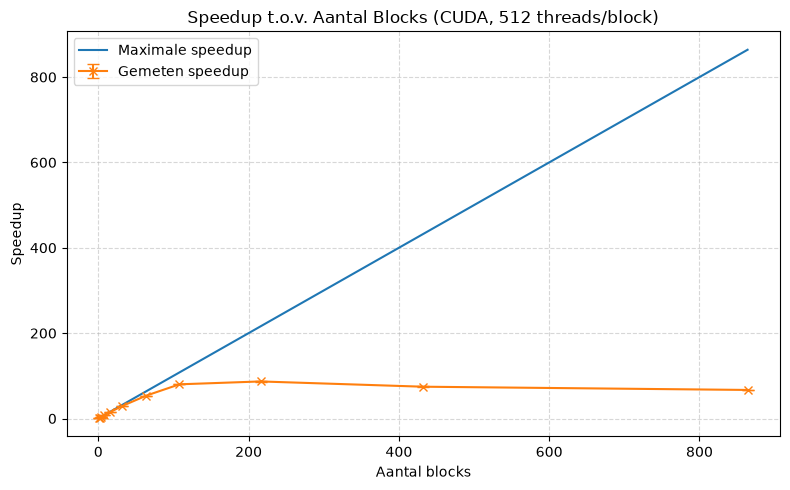

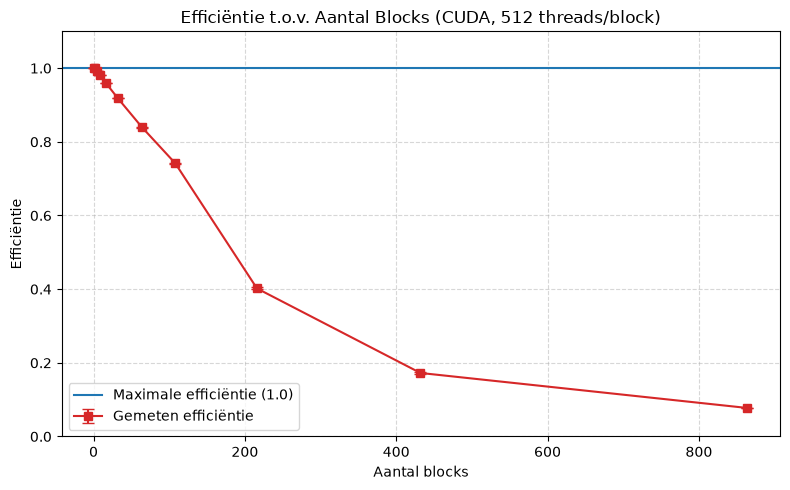

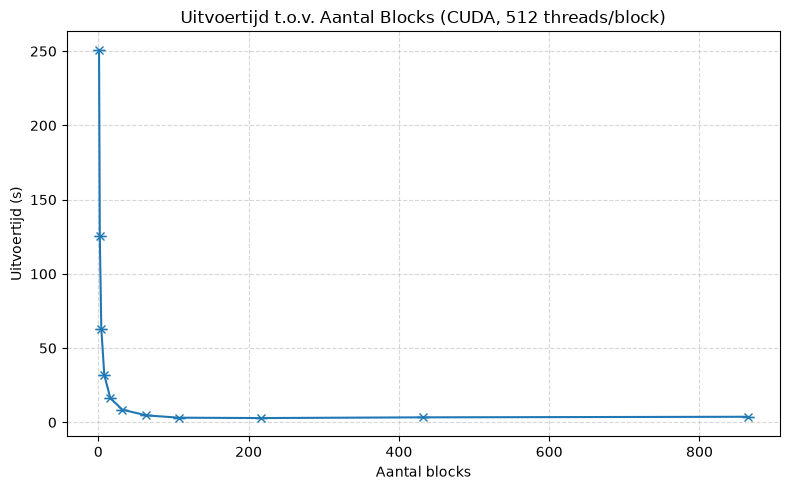

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data uit Slurm output (CUDA, 512 threads/block)
blocks = np.array([1, 2, 4, 8, 16, 32, 64, 108, 216, 432, 864])
mean_times = np.array([250.9167, 125.5143, 63.1590, 31.9345, 16.3264, 8.5346, 4.6691, 3.1319, 2.8899, 3.3677, 3.7498])
std_times = np.array([0.0467, 0.0086, 0.0029, 0.0021, 0.0010, 0.0040, 0.0078, 0.0085, 0.0196, 0.0348, 0.0041])

# Referentietijd (1 block CUDA)
T1 = mean_times[0]
std_Ts = std_times[0]

# Berekening van Speedup en Efficiëntie (schaal 0.0 tot 1.0)
speedup = T1 / mean_times
efficiency = speedup / blocks

# Foutenvoortplanting direct op Efficiëntie
std_efficiency = efficiency * np.sqrt((std_Ts / T1)**2 + (std_times / mean_times)**2)

# Foutenvoortplanting op Speedup
std_speedup = speedup * np.sqrt((std_Ts / T1)**2 + (std_times / mean_times)**2)

# Figuur 1: Speedup 
plt.figure(figsize=(8, 5))
plt.plot(blocks, blocks, color='tab:blue', label='Maximale speedup')
plt.errorbar(blocks, speedup, yerr=std_speedup, fmt='x-', color='tab:orange', 
             capsize=4, label='Gemeten speedup')

plt.xlabel('Aantal blocks')
plt.ylabel('Speedup')
plt.title('Speedup t.o.v. Aantal Blocks (CUDA, 512 threads/block)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Figuur 2: Efficiëntie 
plt.figure(figsize=(8, 5))
plt.axhline(y=1.0, color='tab:blue', linestyle='-', label='Maximale efficiëntie (1.0)')
plt.errorbar(blocks, efficiency, yerr=std_efficiency, fmt='s-', color='tab:red', 
             capsize=4, label='Gemeten efficiëntie')

plt.xlabel('Aantal blocks')
plt.ylabel('Efficiëntie')
plt.title('Efficiëntie t.o.v. Aantal Blocks (CUDA, 512 threads/block)')
plt.ylim(0.0, 1.1)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Figuur 3: Uitvoertijd in functie van het aantal blocks
plt.figure(figsize=(8, 5))
plt.errorbar(blocks, mean_times, yerr=std_times, fmt='x-', color='tab:blue', 
             capsize=4, label='Gemeten uitvoertijd')

plt.xlabel('Aantal blocks')
plt.ylabel('Uitvoertijd (s)')
plt.title('Uitvoertijd t.o.v. Aantal Blocks (CUDA, 512 threads/block)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Besluit

- **Speedup & Efficiëntie:** Tot 108 blocks (het exacte aantal Streaming Multiprocessors op de A100) schaalt de implementatie uitstekend met een relatieve speedup van **$80{,}12\times$** ten opzichte van 1 block (**$136{,}05\times$** t.o.v. serieel) en een hoge efficiëntie van **$74{,}2\%$**. De maximale speedup wordt bereikt bij 216 blocks met een relatieve versnelling van **$86{,}82\times$** (**$147{,}44\times$** t.o.v. serieel).
- **Foutbalken:** De foutbalken (standaardafwijkingen, $\sigma \le 0{,}047\text{ s}$) op de grafieken zijn vrijwel onzichtbaar. Dit toont aan dat de GPU-uitvoering op het VSC-cluster uiterst stabiele en reproduceerbare metingen oplevert zonder verstoring door achtergrondprocessen.


##### Schaalbaarheid van de Implementatie
1. **Bijna-lineaire schaalbaarheid (1 – 108 blocks):** Omdat de NVIDIA A100 over **108 Streaming Multiprocessors (SM's)** beschikt, kan elk block bij $b \le 108$ gelijktijdig op een eigen SM worden ingepland. Tot 32 blocks blijft de efficiëntie boven de $91\%$, en bij 108 blocks (volledige SM-bezetting) bedraagt deze nog steeds **$74{,}2\%$**.

2. **Maximale prestaties door latency hiding (216 blocks):** Bij 216 blocks (2 blocks van 512 threads per SM) daalt de uitvoertijd verder tot het minimum van **$2{,}890\text{ s}$** (relatieve speedup van **$86{,}82\times$**, efficiëntie $40{,}2\%$). Hoewel er geen extra fysieke SM's meer vrij zijn, kunnen de warp-schedulers dankzij twee actieve blocks per SM de geheugenlatenties beter verbergen (*latency hiding*) door tijdens geheugentoegangen over te schakelen tussen warps.

3. **Afnemende prestaties en overhead (432 – 864 blocks):** Bij meer dan 216 blocks neemt de uitvoertijd weer licht toe ($3{,}368\text{ s}$ en $3{,}750\text{ s}$) en zakt de efficiëntie naar $17{,}2\%$ en $7{,}7\%$. Extra blocks passen niet meer tegelijk op de SM's en moeten in de wachtrij wachten, terwijl de PCIe- en CPU-reductie-overhead per iteratie ($\mathcal{O}(\text{blocks} \times k \times D)$) wel lineair blijft toenemen.

### 4. Seriële fractie inschatten (8 blocks)

$T_1 = 250{,}9167\text{ s}$ (gemiddelde tijd voor 1 block),
$T_8 = 31{,}9345\text{ s}$ (gemiddelde tijd voor 8 blocks)

Wet van Amdahl: Theoretische speedup $S_p$ bij $p$ blocks:
$$S_p = \frac{1}{s + \frac{1 - s}{p}}$$

$S_8 = \frac{250{,}9167}{31{,}9345} \approx \mathbf{7{,}857230}$ (relatieve speedup bij 8 blocks),
$p = 8$ (8 blocks)

Formule omzetten naar $s$:
$$s = \frac{\frac{1}{S_p} - \frac{1}{p}}{1 - \frac{1}{p}}$$

Waardes invullen:
$$s = \frac{\frac{1}{7{,}857230} - \frac{1}{8}}{1 - \frac{1}{8}} = \frac{0{,}127271 - 0{,}125}{0{,}875} = \frac{0{,}002271}{0{,}875} \approx \mathbf{0{,}002596}$$

De geschatte seriële fractie op basis van 8 blocks bedraagt dus **$0{,}26\%$** ($s \approx 0{,}0026$).

#### Conclusie
De geschatte seriële fractie $s$ bedraagt **0,26%**. Dit betekent dat circa 99,74% van de uitvoeringstijd effectief parallel geschaald wordt op de GPU. De overige 0,26% wordt veroorzaakt door het seriële deel van de code op de CPU (het samenvoegen van de block-subtotalen en het herberekenen van de nieuwe centroids), de PCIe-geheugenoverdracht tussen host en device, en de kernel-launch overhead.

### 5. Geschatte uitvoertijd (16 blocks)

$s = 0{,}002596$, $p = 16$

$$S_{16, \text{pred}} = \frac{1}{s + \frac{1 - s}{16}} = \frac{1}{0{,}002596 + \frac{1 - 0{,}002596}{16}} = \frac{1}{0{,}002596 + 0{,}062338} = \frac{1}{0{,}064934} \approx \mathbf{15{,}4003}$$

$$T_{16, \text{pred}} = \frac{T_1}{S_{16, \text{pred}}} = \frac{250{,}9167}{15{,}4003} \approx \mathbf{16{,}2930\text{ s}}$$

Voorspelde tijd: **16,2930 s**
Gemeten tijd: **16,3264 s**

$\implies$ verschil: $16{,}3264 - 16{,}2930 = \mathbf{0{,}0334\text{ s}}$ ($+0{,}21\%$)

#### Bespreking van het verschil
In werkelijkheid is het programma dus iets trager dan de wet van Amdahl voorspelt, maar met een verschil van slechts **$0{,}0334\text{ s}$ ($0{,}21\%$)** sluit de theoretische voorspelling zo goed als perfect aan bij de meting.



## 6. Verwachtingen bij Opschalen van SM's & Limiet bij Oneindig Veel SM's

### 1. Verwachtingen bij Stijgend Aantal SM's ($p \rightarrow \infty$)
Naarmate we over meer Streaming Multiprocessors (SM's) beschikken (en het aantal blocks meeschalen zodat elke SM bezet blijft), zien we twee fasen:

- **Fase 1 (Sterke versnelling met afnemende meeropbrengst):** Zolang de dataset groot genoeg is om elk block van voldoende werk te voorzien, daalt de parallelle uitvoertijd sterk. Omdat de seriële fractie ($s \approx 0{,}26\%$) extreem klein is, blijft deze schaling veel langer vrijwel lineair doorlopen dan op een CPU (zoals ook blijkt uit onze metingen tot 108 en 216 blocks).
- **Fase 2 (Verzadiging en stijgende reductie-overhead):** Zodra het aantal blocks en SM's zeer groot wordt, krijgt elk block nog maar een klein aantal datapunten te verwerken (bij $1\,000\,000$ punten en $512$ threads/block heeft elk block al bij $\approx 1954$ blocks slechts één punt per thread). Daarnaast groeit de seriële overhead op de CPU en PCIe-bus (het kopiëren en optellen van `h_blockSums`, `h_blockCounts` en `h_blockDist`) lineair met het aantal blocks ($\mathcal{O}(\text{blocks} \times k \times D)$), waardoor de totale tijd uiteindelijk weer zal **stijgen**.

### 2. Limiet bij oneindig veel SM's

Volgens de wet van Amdahl is de maximale relatieve speedup bij een oneindig aantal SM's begrensd door de seriële fractie:
$$S_{\infty} = \lim_{p \to \infty} \frac{1}{s + \frac{1 - s}{p}} = \frac{1}{s}$$

Met onze geschatte seriële fractie $s = 0{,}002596$ (bepaald bij 8 blocks):

$$S_{\infty} = \frac{1}{0{,}002596} \approx \mathbf{385{,}21}$$

De theoretisch minimale uitvoertijd ($T_{\infty}$) wordt dan:

$$T_{\infty} = \frac{T_1}{S_{\infty}} = s \cdot T_1 = 0{,}002596 \times 250{,}9167\text{ s} \approx \mathbf{0{,}6514\text{ seconden}}$$

### 3. Praktische limiet van de huidige implementatie
In de praktijk zal de uitvoertijd nooit onder de $0{,}6514\text{ s}$ zakken (en zelfs hoger liggen dan het gemeten optimum van $2{,}890\text{ s}$ bij 216 blocks), om twee redenen:

1. **Beperkte datasetgrootte ($N = 1\,000\,000$):** Bij $512$ threads per block zijn er maximaal $\lceil 1\,000\,000 / 512 \rceil = 1954$ blocks nodig om elk datapunt door een eigen thread te laten verwerken. Extra SM's boven de $1954$ blijven volledig **onbenut (idle)** omdat de parallellisatie binnen één iteratie over de rijen van de dataset gebeurt.
2. **Groeiende CPU- en PCIe-bottleneck:** De wet van Amdahl veronderstelt een constante seriële fractie $s$, maar in onze implementatie schaalt de communicatie- en reductiekost op de host mee met het aantal blocks. Bij duizenden blocks neemt het versturen en optellen van de block-subtotalen op de CPU meer tijd in beslag dan de winst op de GPU.

## 7. Op welke manieren schaalbaarheid verbeteren

Om de schaalbaarheid bij een groter aantal blocks en SM's te verbeteren (en de vertraging boven 216 blocks te voorkomen), moeten we de communicatie tussen CPU en GPU verkleinen en het geheugengebruik van de GPU slimmer inrichten.

### 1. Tussentotalen rechtstreeks op de GPU optellen (CPU ontlasten)
- **Idee:** Momenteel stuurt elk block na elke iteratie zijn eigen tussentotalen (`d_blockSums`, `d_blockCounts` en `d_blockDist`) terug naar de CPU. De CPU telt deze vervolgens één voor één bij elkaar op en stuurt de nieuwe centroids terug naar de GPU. Hoe meer blocks we gebruiken, hoe meer kopieer- en optelwerk de CPU moet doen.
- **Werking:** 
  - Laat een tweede, kleine GPU-kernel de tussentotalen van alle blocks rechtstreeks op de GPU bij elkaar optellen en meteen de nieuwe centroids berekenen.
  - Per iteratie hoeft alleen nog maar één klein vlaggetje (`d_changed`, 4 bytes) naar de CPU gekopieerd te worden om te controleren of de `while`-lus klaar is. Het werk van de CPU blijft zo altijd even klein, ongeacht hoeveel blocks of SM's we gebruiken.
- **Vereiste werkhoeveelheid:** **Middelmatig (2 – 3 uurtjes werk).** De bestaande hoofdkernel blijft grotendeels intact; we hoeven enkel een kleine optel-kernel op de GPU toe te voegen en de `cudaMemcpy`-aanroepen in de `while`-lus weg te halen.

---

### 2. Data slimmer in het GPU-geheugen plaatsen (SoA & Constant Memory)
- **Idee:** Nu staan de coördinaten van elk datapunt per rij achter elkaar in het geheugen (`[x1, y1, z1, w1, x2, y2, ...]`). Wanneer GPU-threads naast elkaar dezelfde dimensie (bijv. alle `x`-waarden) willen lezen, moeten ze telkens over andere kolommen heen springen, wat geheugenbandbreedte kost. Daarnaast worden de centroids elke iteratie uit het tragere hoofdgeheugen van de GPU gelezen.
- **Werking:** 
  - **Structure-of-Arrays (SoA):** Zet eerst alle `x`-waarden achter elkaar, dan alle `y`-waarden, enzovoort (`dimensie * numRows + rij`). Opeenvolgende threads lezen dan direct naast elkaar in het geheugen (*coalesced memory access*), wat een veel hogere geheugensnelheid oplevert.
  - **Constant Memory (`__constant__`):** Plaats de centroids in het snelle, gecachete *constant memory* van de GPU, omdat elke thread continu naar dezelfde centroid-coördinaten kijkt.
- **Vereiste werkhoeveelheid:** **Laag tot middelmatig (1 – 2 uurtjes werk).** Dit vraagt enkel een éénmalige herschikking van de inputdata vóór het kopiëren naar de GPU en een kleine aanpassing van de indexberekening in de kernel.

---

### 3. Meerdere herhalingen tegelijk uitvoeren op de GPU (2D-grid)
- **Idee:** Momenteel worden de verschillende herhalingen (`repetitions`) één voor één na elkaar uitgevoerd. Bij een kleinere dataset of een GPU met zeer veel SM's zijn er onvoldoende datapunten om alle SM's tegelijk bezig te houden.
- **Werking:** Gebruik een 2D-grid van blocks waarbij de ene richting de datapunten verdeelt en de andere richting alle herhalingen tegelijkertijd op de GPU draait. Zo worden extra SM's benut door meerdere onafhankelijke K-means runs parallel uit te voeren.
- **Vereiste werkhoeveelheid:** **Hoog (4 – 6 uurtjes werk).** Alle geheugenbuffers op de GPU (`d_centroids`, `d_clusters`, `d_blockSums`) moeten per herhaling gescheiden worden bijgehouden zodat de verschillende runs elkaar niet overschrijven.